# Instagram engagement analysis

Which formats, posting hours and hashtag counts get the most engagement?

Engagement rate = (likes + comments) / views × 100

The data is simulated so the notebook runs anywhere. For a real csv, skip *Random numbers and the data* and load your file with `read_csv`, using columns `date, user, kind, hour, tags, views, likes, comments`. Needs pandas 2.2 or newer.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from datetime import datetime, timedelta

sns.set_theme(style="whitegrid", palette="deep", font_scale=.95)
pd.options.display.float_format = "{:,.2f}".format
rng = np.random.default_rng(11)

## Unit I · NumPy

### Creating ndarrays

In [2]:
a = np.array([[1, 2, 3], [4, 5, 6]])
print(f"shape {a.shape} | ndim {a.ndim} | size {a.size}")
print("zeros", np.zeros((2, 3)).tolist(), "| ones", np.ones(3), "| eye", np.eye(2).tolist())
print("arange", np.arange(0, 10, 2), "| linspace", np.linspace(0, 1, 5))

shape (2, 3) | ndim 2 | size 6
zeros [[0.0, 0.0, 0.0], [0.0, 0.0, 0.0]] | ones [1. 1. 1.] | eye [[1.0, 0.0], [0.0, 1.0]]
arange [0 2 4 6 8] | linspace [0.   0.25 0.5  0.75 1.  ]


### Data types

In [3]:
print(a.dtype, "|", a.astype("float32").dtype, "|", np.array([1, 2], dtype="int8").dtype)
print(np.array([1.9, -2.7]).astype(int), np.array(["1.5", "2"]).astype(float))   # astype(int) cuts toward zero

int64 | float32 | int8
[ 1 -2] [1.5 2. ]


### Random numbers

In [4]:
print("integers", rng.integers(0, 10, 5), "| normal", rng.normal(0, 1, 3).round(2))
print("choice", rng.choice(["a", "b", "c"], 4), "| permutation", rng.permutation(5))
print("same seed, same numbers:", np.random.default_rng(1).random(2) == np.random.default_rng(1).random(2))
np.random.seed(0)
print("legacy api", np.random.rand(2).round(3), np.random.randn(2).round(3))

integers [1 1 7 4 5] | normal [-0.51 -0.3  -0.53]
choice ['b' 'b' 'a' 'b'] | permutation [2 3 0 1 4]
same seed, same numbers: [ True  True]
legacy api [0.549 0.715] [0.979 2.241]


### Random numbers and the data

In [5]:
n = 600
users = np.array(["fit", "food", "tech", "trip", "meme"])
kinds = np.array(["Reel", "Photo", "Video", "Carousel"])
uid = rng.integers(0, 5, n)
kid = rng.choice(4, n, p=[.45, .2, .1, .25])
hour = rng.integers(6, 24, n)
tags = rng.integers(0, 26, n)
date = np.sort(rng.choice(pd.date_range("2024-01-01", periods=305).to_numpy(), n))
dow = pd.DatetimeIndex(date).dayofweek

reach = np.array([12e3, 45e3, 80e3, 150e3, 300e3])[uid] * rng.lognormal(-1.6, .7, n)
boost = (np.array([2.4, .9, 1.2, 1.1])[kid]
         * (1 + .5 * np.exp(-(hour - 20) ** 2 / 18))      # evenings
         * (1 + .6 * np.exp(-(tags - 10) ** 2 / 50))      # around 10 hashtags
         * np.where(dow >= 5, 1.15, 1))                   # weekends
views = (reach * boost).astype(int)
likes = (views * np.array([.05, .06, .045, .09])[kid] * (1 + .12 * np.exp(-(hour - 20) ** 2 / 18)) * rng.uniform(.7, 1.3, n)).astype(int)
comments = (likes * rng.uniform(.02, .1, n) * np.where(dow >= 5, 1.3, 1)).astype(int)
hour[rng.choice(n, 10, replace=False)] = -1               # unknown hour, cleaned later
print(f"{n} posts | views {views.min():,} to {views.max():,} | median {int(np.median(views)):,}")

600 posts | views 1,100 to 1,566,306 | median 37,612


### Arithmetic

In [6]:
m = np.stack([views, likes, comments])
rates = m[1:] / m[0] * 100                      # (2, n) / (n,) broadcasts per column
er = (likes + comments) / views * 100
print("likes % and comments % of views, first 4 posts\n", rates[:, :4].round(2))
print("engagement rate:", er[:4].round(2), "| mean", er.mean().round(2))
print("totals (views, likes, comments):", m.sum(axis=1))

likes % and comments % of views, first 4 posts
 [[3.9  5.07 7.38 7.3 ]
 [0.19 0.43 0.59 0.68]]
engagement rate: [4.09 5.51 7.96 7.98] | mean 6.75
totals (views, likes, comments): [48611275  2866937   184953]


### Basic indexing and slicing

In [7]:
print("first 5:", views[:5], "| every 100th:", views[::100], "| last:", views[-1])
print("likes and comments of first 3 posts\n", m[1:, :3])
v = views.copy()
v[:3][:] = 0                                    # a slice is a view, so v changes
print("copy after writing to slice:", v[:4], "| original:", views[:4])

first 5: [467068  19942  13284   6478  19810] | every 100th: [467068   7577   5047 111059  68211  80625] | last: 11570
likes and comments of first 3 posts
 [[18215  1012   980]
 [  887    86    78]]
copy after writing to slice: [   0    0    0 6478] | original: [467068  19942  13284   6478]


### Boolean indexing

In [8]:
cut = np.percentile(views, 90)
hit = views > cut
print(f"top 10% (> {cut:,.0f} views): {hit.sum()} posts | er {er[hit].mean():.2f}% vs {er[~hit].mean():.2f}% for the rest")
mask = (kinds[kid] == "Reel") & (er > 7)
print("reels above 7% er:", mask.sum(), "| any post above 12%:", (er > 12).any())

top 10% (> 202,885 views): 60 posts | er 6.17% vs 6.81% for the rest
reels above 7% er: 24 | any post above 12%: True


### Fancy indexing

In [9]:
top = np.argsort(views)[-5:][::-1]
print("top 5 views:", views[top])
print("their formats:", kinds[kid[top]], "| accounts:", users[uid[top]])
print("posts 0, 10, 20\n", m[:, [0, 10, 20]])
print("paired picks (row, col):", m[[0, 1], [5, 6]])

top 5 views: [1566306  799170  733539  667809  630122]
their formats: ['Reel' 'Reel' 'Reel' 'Reel' 'Reel'] | accounts: ['meme' 'meme' 'meme' 'meme' 'meme']
posts 0, 10, 20
 [[467068   6755 175235]
 [ 18215    379   8950]
 [   887     34    380]]
paired picks (row, col): [30442  6011]


### Transposing arrays and swapping axes

In [10]:
cube = m.reshape(3, 20, 30)
print("transpose", m.shape, "->", m.T.shape)
print("swapaxes(0, 2)", cube.shape, "->", cube.swapaxes(0, 2).shape)
print("transpose(1, 0, 2)", cube.shape, "->", cube.transpose(1, 0, 2).shape)

transpose (3, 600) -> (600, 3)
swapaxes(0, 2) (3, 20, 30) -> (30, 20, 3)
transpose(1, 0, 2) (3, 20, 30) -> (20, 3, 30)


### Universal functions

In [11]:
print("log10", np.log10(views[:4]).round(2), "| sqrt", np.sqrt(likes[:4]).round(1))
print("maximum", np.maximum(likes, comments)[:4], "| cumsum", np.cumsum(views[:4]))
print("where", np.where(er[:4] > 7, "high", "low"), "| exp", np.exp([0, 1]).round(2))
print(dict(zip(*np.unique(kinds[kid], return_counts=True))))

log10 [5.67 4.3  4.12 3.81] | sqrt [135.   31.8  31.3  21.7]
maximum [18215  1012   980   473] | cumsum [467068 487010 500294 506772]
where ['low' 'low' 'high' 'high'] | exp [1.   2.72]
{np.str_('Carousel'): np.int64(135), np.str_('Photo'): np.int64(122), np.str_('Reel'): np.int64(288), np.str_('Video'): np.int64(55)}


## Unit II · Pandas basics

### Series

In [12]:
s = pd.Series(views[:5], index=[f"post{i}" for i in range(5)], name="views")
display(s.to_frame())
print(s["post1"], "|", s[s > s.mean()].index.tolist(), "|", (s / 1000).round(1).tolist())

,views
post0,467068
post1,19942
post2,13284
post3,6478
post4,19810


19942 | ['post0'] | [467.1, 19.9, 13.3, 6.5, 19.8]


### DataFrame and Index objects

In [13]:
raw = pd.DataFrame({"date": date, "user": users[uid], "kind": kinds[kid], "hour": hour,
                    "tags": tags.astype(float), "views": views, "likes": likes, "comments": comments})
raw.loc[rng.choice(n, 25, replace=False), "tags"] = np.nan
print(raw.index, "\n", raw.columns.tolist(), "| unique:", raw.columns.is_unique)
print(raw.columns.union(["eng"]).tolist(), "|", raw.index[:3].tolist())
raw.head()

RangeIndex(start=0, stop=600, step=1) 
 ['date', 'user', 'kind', 'hour', 'tags', 'views', 'likes', 'comments'] | unique: True
['comments', 'date', 'eng', 'hour', 'kind', 'likes', 'tags', 'user', 'views'] | [0, 1, 2]


,date,user,kind,hour,tags,views,likes,comments
0,2024-01-01,trip,Reel,8,8.00,467068,18215,887
1,2024-01-01,meme,Photo,17,NaN,19942,1012,86
2,2024-01-01,food,Photo,18,1.00,13284,980,78
3,2024-01-03,fit,Carousel,19,1.00,6478,473,44
4,2024-01-04,tech,Reel,15,15.00,19810,972,29


### Writing data to text

In [14]:
print(raw.head(3).to_csv(sep="|", index=False, columns=["date", "user", "views"]))
raw.to_csv("posts.csv", index=False, na_rep="NA")

date|user|views
2024-01-01|trip|467068
2024-01-01|meme|19942
2024-01-01|food|13284



### Reading text files in pieces

In [15]:
print(pd.read_csv("posts.csv", nrows=2, usecols=["date", "kind", "views"]))
tot = 0
for ch in pd.read_csv("posts.csv", chunksize=150):
    tot += ch.views.sum()
    print(f"chunk of {len(ch)} rows, running views total {tot:,}")
df = pd.concat(pd.read_csv("posts.csv", chunksize=150, parse_dates=["date"]), ignore_index=True)
df["eng"] = (df.likes + df.comments) / df.views * 100
df.head()

         date   kind   views
0  2024-01-01   Reel  467068
1  2024-01-01  Photo   19942
chunk of 150 rows, running views total 11,945,141
chunk of 150 rows, running views total 25,708,619
chunk of 150 rows, running views total 37,868,606
chunk of 150 rows, running views total 48,611,275


,date,user,kind,hour,tags,views,likes,comments,eng
0,2024-01-01,trip,Reel,8,8.00,467068,18215,887,4.09
1,2024-01-01,meme,Photo,17,NaN,19942,1012,86,5.51
2,2024-01-01,food,Photo,18,1.00,13284,980,78,7.96
3,2024-01-03,fit,Carousel,19,1.00,6478,473,44,7.98
4,2024-01-04,tech,Reel,15,15.00,19810,972,29,5.05


### Reindexing

In [16]:
d = df.groupby("kind").views.mean()
display(d.reindex(["Reel", "Photo", "Video", "Carousel", "Story"]).to_frame("avg views"))   # new label -> NaN
dv = df.groupby("date").views.sum()
display(dv.reindex(pd.date_range("2024-01-01", "2024-01-08"), method="ffill").to_frame("views"))

,avg views
kind,
Reel,"115,371.64"
Photo,"49,308.80"
Video,"54,460.78"
Carousel,"47,209.10"
Story,NaN


,views
2024-01-01,500294
2024-01-02,500294
2024-01-03,6478
2024-01-04,50252
2024-01-05,524291
2024-01-06,481297
2024-01-07,210644
2024-01-08,572596


### Dropping entries from an axis

In [17]:
print("drop columns:", df.drop(columns=["likes", "comments"]).shape, "| drop rows:", df.drop(index=[0, 1]).shape)
d.drop("Reel").to_frame("avg views")

drop columns: (600, 7) | drop rows: (598, 9)


,avg views
kind,
Carousel,"47,209.10"
Photo,"49,308.80"
Video,"54,460.78"


### Indexing, selection and filtering

In [18]:
display(df.loc[2:4, ["user", "kind", "views"]])                          # labels, end included
display(df.iloc[:3, :3])                                                 # positions, end excluded
display(df[(df.kind == "Reel") & (df.views > 2e5)].head(3))
df[df.user.isin(["fit", "tech"])].query("eng > 9").head(3)

,user,kind,views
2,food,Photo,13284
3,fit,Carousel,6478
4,tech,Reel,19810


,date,user,kind
0,2024-01-01,trip,Reel
1,2024-01-01,meme,Photo
2,2024-01-01,food,Photo


,date,user,kind,hour,tags,views,likes,comments,eng
0,2024-01-01,trip,Reel,8,8.00,467068,18215,887,4.09
7,2024-01-05,meme,Reel,20,3.00,415496,17042,1015,4.35
9,2024-01-06,meme,Reel,6,17.00,257027,14946,571,6.04


,date,user,kind,hour,tags,views,likes,comments,eng
15,2024-01-07,tech,Carousel,8,14.00,87006,8965,1009,11.46
32,2024-01-18,tech,Carousel,12,9.00,26798,2861,180,11.35
78,2024-02-11,fit,Carousel,13,23.00,3177,337,16,11.11


### Arithmetic and data alignment

In [19]:
a = df.groupby("kind").likes.sum()
b = df.groupby("kind").comments.sum()
display(pd.DataFrame({"plain +": a.drop("Reel") + b, "fill_value=0": a.drop("Reel").add(b, fill_value=0)}))
f1, f2 = df[["likes", "comments"]].head(3), df[["likes", "views"]].head(2)
f1 + f2                                                                  # aligned on rows and columns

,plain +,fill_value=0
kind,,
Carousel,"659,085.00","659,085.00"
Photo,"411,528.00","411,528.00"
Reel,NaN,"107,987.00"
Video,"153,436.00","153,436.00"


,comments,likes,views
0,NaN,"36,430.00",NaN
1,NaN,"2,024.00",NaN
2,NaN,NaN,NaN


### Function application and mapping

In [20]:
display(df[["views", "likes", "comments"]].apply(lambda c: c.max() - c.min()).to_frame("range"))
display(df.head(3).apply(lambda r: f"{r.user} / {r.kind}", axis=1).to_frame("label"))
display(df[["views", "likes"]].head(3).map(lambda v: f"{v / 1000:.1f}k"))
df.kind.map({"Reel": "short video", "Photo": "still"}).head(4).to_frame("mapped")   # unmapped -> NaN

,range
views,1565206
likes,90389
comments,5746


,label
0,trip / Reel
1,meme / Photo
2,food / Photo


,views,likes
0,467.1k,18.2k
1,19.9k,1.0k
2,13.3k,1.0k


,mapped
0,short video
1,still
2,still
3,NaN


### Sorting and ranking

In [21]:
display(df.sort_values(["kind", "eng"], ascending=[True, False])[["kind", "user", "eng"]].head(4))
display(df.sort_index(axis=1).head(2))
df.assign(rank=df.eng.rank(ascending=False, method="min")).nsmallest(3, "rank")[["date", "user", "kind", "eng", "rank"]]

,kind,user,eng
343,Carousel,tech,13.82
290,Carousel,trip,13.23
240,Carousel,food,12.69
85,Carousel,meme,12.69


,comments,date,eng,hour,kind,likes,tags,user,views
0,887,2024-01-01,4.09,8,Reel,18215,8.00,trip,467068
1,86,2024-01-01,5.51,17,Photo,1012,NaN,meme,19942


,date,user,kind,eng,rank
343,2024-06-30,tech,Carousel,13.82,1.00
290,2024-06-03,trip,Carousel,13.23,2.00
240,2024-05-09,food,Carousel,12.69,3.00


### Axis indexes with duplicate labels

In [22]:
k = df.set_index("kind")
print("unique:", k.index.is_unique, "| Reel rows:", k.loc["Reel"].shape[0], "| labels:", k.index.nunique())
display(k.loc[["Carousel", "Video"]].head(3)[["user", "views", "eng"]])
k.index.value_counts().to_frame("rows")

unique: False | Reel rows: 288 | labels: 4


,user,views,eng
kind,,,
Carousel,fit,6478,7.98
Carousel,tech,30442,8.01
Carousel,tech,87006,11.46


,rows
kind,
Reel,288
Carousel,135
Photo,122
Video,55


### Summarizing and computing descriptive statistics

In [23]:
cols = ["hour", "tags", "views", "likes", "comments", "eng"]
display(df[cols].describe())
display(df[["views", "likes", "comments", "eng"]].agg(["sum", "mean", "median", "std"]))
print("most viewed post:", df.views.idxmax(), "| total views:", f"{df.views.cumsum().iloc[-1]:,}")
df[["views", "likes", "comments", "eng", "tags"]].corr()

,hour,tags,views,likes,comments,eng
count,600.00,575.00,600.00,600.00,600.00,600.00
mean,14.55,12.63,"81,018.79","4,778.23",308.25,6.75
std,5.38,7.44,"125,292.80","7,264.60",503.30,2.29
min,-1.00,0.00,"1,100.00",64.00,2.00,3.34
25%,10.00,6.00,"12,523.25",727.00,40.75,5.04
50%,15.00,13.00,"37,612.00","2,445.50",141.50,6.14
75%,19.00,19.00,"101,743.00","5,857.75",356.00,7.80
max,23.00,25.00,"1,566,306.00","90,453.00","5,748.00",13.82


,views,likes,comments,eng
sum,"48,611,275.00","2,866,937.00","184,953.00","4,048.11"
mean,"81,018.79","4,778.23",308.25,6.75
median,"37,612.00","2,445.50",141.50,6.14
std,"125,292.80","7,264.60",503.30,2.29


most viewed post: 153 | total views: 48,611,275


,views,likes,comments,eng,tags
views,1.00,0.95,0.84,-0.13,-0.08
likes,0.95,1.00,0.91,0.05,-0.07
comments,0.84,0.91,1.00,0.08,-0.05
eng,-0.13,0.05,0.08,1.00,0.07
tags,-0.08,-0.07,-0.05,0.07,1.00


## Unit III · Cleaning and wrangling

### Filtering out missing data

In [24]:
print(df.isna().sum()[lambda s: s > 0].to_dict(), "missing")
print("dropna():", df.dropna().shape, "| thresh=8:", df.dropna(thresh=8).shape, "| axis=1:", df.dropna(axis=1).shape)

{'tags': 25} missing
dropna(): (575, 9) | thresh=8: (600, 9) | axis=1: (600, 8)


### Filling in missing data

In [25]:
print("fill 0 / ffill leaves:", df.tags.fillna(0).isna().sum(), df.tags.ffill().isna().sum())
df["tags"] = df.tags.fillna(df.groupby("kind").tags.transform("median")).astype(int)   # median of the same format
print("missing tags left:", df.tags.isna().sum())

fill 0 / ffill leaves: 0 0
missing tags left: 0


### Replacing values

In [26]:
print((df.hour == -1).sum(), "posts have hour = -1")
df["hour"] = df.hour.replace(-1, np.nan)
df["hour"] = df.hour.fillna(df.hour.median()).astype(int)
df.hour.describe().to_frame().T

10 posts have hour = -1


,count,mean,std,min,25%,50%,75%,max
hour,600.00,14.81,4.99,6.00,11.00,15.00,19.00,23.00


### Transforming data using a function or mapping

In [27]:
df["slot"] = df.hour.map(lambda h: "morning" if h < 12 else "afternoon" if h < 18 else "evening")
df["niche"] = df.user.map({"fit": "health", "food": "lifestyle", "tech": "gadgets", "trip": "travel", "meme": "humor"})
df["user"] = df.user.str.title()
df[["user", "niche", "hour", "slot"]].head(4)

,user,niche,hour,slot
0,Trip,travel,8,morning
1,Meme,humor,17,afternoon
2,Food,lifestyle,18,evening
3,Fit,health,19,evening


### Renaming axis indexes

In [28]:
print(df.rename(columns=str.upper).columns.tolist())                     # both calls return copies
df.rename(index={0: "first"}, columns={"eng": "engagement"}).rename_axis(index="post").head(2)

['DATE', 'USER', 'KIND', 'HOUR', 'TAGS', 'VIEWS', 'LIKES', 'COMMENTS', 'ENG', 'SLOT', 'NICHE']


,date,user,kind,hour,tags,views,likes,comments,engagement,slot,niche
post,,,,,,,,,,,
first,2024-01-01,Trip,Reel,8,8,467068,18215,887,4.09,morning,travel
1,2024-01-01,Meme,Photo,17,12,19942,1012,86,5.51,afternoon,humor


### Discretization and binning

In [29]:
df["tier"] = pd.cut(df.views, [0, 5e3, 5e4, np.inf], labels=["low", "mid", "high"])
df["band"] = pd.qcut(df.eng, 4, labels=["q1", "q2", "q3", "q4"])
display(df.tier.value_counts().to_frame("posts"))
display(df.groupby("band", observed=True).eng.agg(["min", "max", "count"]))
pd.cut(df.hour, [5, 11, 17, 23]).value_counts().sort_index().to_frame("posts")

,posts
tier,
mid,293
high,254
low,53


,min,max,count
band,,,
q1,3.34,5.03,150
q2,5.04,6.14,150
q3,6.15,7.80,150
q4,7.83,13.82,150


,posts
hour,
"(5, 11]",178
"(11, 17]",214
"(17, 23]",208


### Detecting and filtering outliers

In [30]:
q1, q3 = df.eng.quantile([.25, .75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
out = (df.eng < lo) | (df.eng > hi)
print(f"fences {lo:.2f} to {hi:.2f} | outliers: {out.sum()}")
display(df[out][["user", "kind", "views", "eng"]])
df = df[~out].reset_index(drop=True)
print(len(df), "posts kept")

fences 0.88 to 11.95 | outliers: 24


,user,kind,views,eng
44,Food,Carousel,15726,12.44
74,Food,Carousel,6632,12.62
82,Tech,Carousel,38541,12.60
85,Meme,Carousel,88389,12.69
150,Tech,Carousel,11773,12.61
176,Meme,Carousel,222546,12.45
213,Fit,Carousel,6068,12.10
223,Trip,Carousel,64757,12.20
240,Food,Carousel,42203,12.69
268,Meme,Carousel,464412,12.63


576 posts kept


### Categorical extension type

In [31]:
df["kind"] = df.kind.astype("category")
print(df.kind.cat.categories.tolist(), "| codes:", df.kind.cat.codes.head(4).tolist())
print("ordered tier:", df.tier.cat.ordered, "|", "bytes as object vs category:",
      df.kind.astype(object).memory_usage(deep=True), df.kind.memory_usage(deep=True))

['Carousel', 'Photo', 'Reel', 'Video'] | codes: [2, 1, 1, 0]
ordered tier: True | bytes as object vs category: 31281 1098


### Computations with categoricals

In [32]:
print("tier max:", df.tier.max(), "| posts at mid or above:", (df.tier >= "mid").sum())
sub = df[df.kind != "Video"].kind
print("categories:", len(sub.cat.categories), "->", len(sub.cat.remove_unused_categories().cat.categories))
order = ["Reel", "Video", "Photo", "Carousel"]
df["kind"] = df.kind.cat.set_categories(order)
display(df.groupby("kind", observed=True).eng.agg(["count", "mean"]))
pd.get_dummies(df.kind).sum().to_frame("posts")

tier max: high | posts at mid or above: 526
categories: 4 -> 3


,count,mean
kind,,
Reel,288,5.46
Video,55,4.94
Photo,122,6.83
Carousel,111,9.64


,posts
Reel,288
Video,55
Photo,122
Carousel,111


### Hierarchical indexing: reordering and sorting levels

In [33]:
h = df.set_index(["user", "kind"]).sort_index()
display(h.loc["Fit"].head(2)[["views", "eng"]])
display(h.swaplevel().sort_index(level=0).head(3)[["views", "eng"]])
h.sort_index(level=1).head(3)[["views", "eng"]]

,views,eng
kind,,
Reel,6755,6.11
Reel,8806,6.21


views  eng
kind user            
Reel Fit    6755 6.11
     Fit    8806 6.21
     Fit    3158 4.15

views  eng
user kind            
Fit  Reel   6755 6.11
     Reel   8806 6.21
     Reel   3158 4.15

### Summary statistics by level

In [34]:
display(h.groupby(level="user")[["views", "likes"]].sum())
h.groupby(level=["user", "kind"], observed=True).eng.mean().unstack()

,views,likes
user,,
Fit,1334904,74946
Food,3539043,201737
Meme,23753007,1350787
Tech,6408991,377804
Trip,11895631,665721


kind,Reel,Video,Photo,Carousel
user,,,,
Fit,5.48,4.77,6.63,10.05
Food,5.33,5.08,6.96,9.15
Meme,5.52,5.13,6.49,9.69
Tech,5.46,4.88,7.32,10.02
Trip,5.52,4.93,6.81,9.11


### Indexing with a DataFrame's columns

In [35]:
display(df.set_index("date").head(2))
display(df.set_index(["user", "kind"], drop=False).head(2).iloc[:, :4])
h.reset_index().iloc[:2, :4]

,user,kind,hour,tags,views,likes,comments,eng,slot,niche,tier,band
date,,,,,,,,,,,,
2024-01-01,Trip,Reel,8,8,467068,18215,887,4.09,morning,travel,high,q1
2024-01-01,Meme,Photo,17,12,19942,1012,86,5.51,afternoon,humor,mid,q2


,,date,user,kind,hour
user,kind,,,,
Trip,Reel,2024-01-01,Trip,Reel,8
Meme,Photo,2024-01-01,Meme,Photo,17


,user,kind,date,hour
0,Fit,Reel,2024-01-06,21
1,Fit,Reel,2024-01-12,22


### Database-style DataFrame joins

In [36]:
fol = pd.DataFrame({"user": ["Fit", "Food", "Tech", "Trip", "Meme", "Art"], "followers": [12, 45, 80, 150, 300, 20]})   # thousands
print("inner:", df.merge(fol, on="user").user.nunique(), "accounts | outer:", df.merge(fol, on="user", how="outer").user.nunique())
display(df.merge(fol, on="user", how="right").loc[lambda d: d.date.isna(), ["user", "followers", "views"]])   # Art has no posts
avg = df.groupby("user").views.mean().reset_index()
display(df.merge(avg, on="user", suffixes=("", "_avg"))[["user", "views", "views_avg"]].head(3))
df.merge(fol.rename(columns={"user": "name"}), left_on="user", right_on="name").shape

inner: 5 accounts | outer: 6


,user,followers,views
576,Art,20,NaN


,user,views,views_avg
0,Trip,467068,"105,271.07"
1,Meme,19942,"204,767.30"
2,Food,13284,"33,705.17"


(576, 15)

### Merging on index

In [37]:
df = df.join(fol.set_index("user"), on="user")
df["vpf"] = df.views / (df.followers * 1000)
print(pd.merge(df.set_index("user")[["views"]], fol.set_index("user"), left_index=True, right_index=True).shape)
df[["user", "views", "followers", "vpf"]].head(3)

(576, 2)


,user,views,followers,vpf
0,Trip,467068,150,3.11
1,Meme,19942,300,0.07
2,Food,13284,45,0.30


### Concatenating along an axis

In [38]:
a, b = df[df.date < "2024-04-01"], df[df.date >= "2024-04-01"]
print(len(a), "+", len(b), "=", len(pd.concat([a, b])), "| axis=1:", pd.concat([df.user, df.views], axis=1).shape)
pd.concat([a, b], keys=["early", "late"]).groupby(level=0).eng.agg(["count", "mean"])

165 + 411 = 576 | axis=1: (576, 2)


,count,mean
early,165,6.43
late,411,6.54


### Combining data with overlap

In [39]:
x1 = pd.Series([1, np.nan, 3], index=list("abc"))
x2 = pd.Series([10, 20, 30, 40], index=list("abcd"))
display(pd.DataFrame({"x1": x1, "x2": x2, "x1.combine_first(x2)": x1.combine_first(x2)}))
strong = df.eng.where(df.eng > 8)
print("posts below 8%:", strong.isna().sum(), "-> after filling with the format mean:",
      strong.combine_first(df.groupby("kind", observed=True).eng.transform("mean")).isna().sum())

,x1,x2,x1.combine_first(x2)
a,1.00,10,1.00
b,NaN,20,20.00
c,3.00,30,3.00
d,NaN,40,40.00


posts below 8%: 465 -> after filling with the format mean: 0


### Reshaping with hierarchical indexing

In [40]:
t = df.groupby(["kind", "tier"], observed=True).eng.mean().unstack()
display(t)
display(t.stack().to_frame("eng").head(4))
display(df.pivot_table(index="kind", columns="slot", values="eng", observed=True)[["morning", "afternoon", "evening"]])
t.reset_index().melt(id_vars="kind", var_name="tier", value_name="eng").head(4)

tier,low,mid,high
kind,,,
Reel,5.26,5.43,5.50
Video,5.38,4.67,5.21
Photo,6.54,7.05,6.48
Carousel,9.74,9.65,9.58


eng
kind  tier     
Reel  low  5.26
      mid  5.43
      high 5.50
Video low  5.38

slot,morning,afternoon,evening
kind,,,
Reel,5.02,5.56,5.76
Video,4.98,4.80,5.09
Photo,6.31,6.65,7.41
Carousel,9.54,9.68,9.68


,kind,tier,eng
0,Reel,low,5.26
1,Video,low,5.38
2,Photo,low,6.54
3,Carousel,low,9.74


## Unit IV · Aggregation and time series

### Column-wise and multiple function application

In [41]:
g = df.groupby("kind", observed=True)
display(g.eng.agg(["mean", "std", "max"]))
display(g.agg({"views": "median", "likes": ["mean", "sum"]}))
g.agg(posts=("eng", "size"), avg_eng=("eng", "mean"), med_views=("views", "median"), best=("eng", "max"))

,mean,std,max
kind,,,
Reel,5.46,1.01,7.75
Video,4.94,0.94,6.71
Photo,6.83,1.26,9.28
Carousel,9.64,1.45,11.89


views    likes         
            median     mean      sum
kind                                
Reel     59,256.00 5,971.72  1719854
Video    21,968.00 2,621.85   144202
Photo    22,210.50 3,157.89   385262
Carousel 29,339.00 3,798.89   421677

,posts,avg_eng,med_views,best
kind,,,,
Reel,288,5.46,"59,256.00",7.75
Video,55,4.94,"21,968.00",6.71
Photo,122,6.83,"22,210.50",9.28
Carousel,111,9.64,"29,339.00",11.89


### Returning aggregated data without row indexes

In [42]:
df.groupby(["user", "kind"], as_index=False, observed=True).views.sum().head(5)

,user,kind,views
0,Fit,Reel,923982
1,Fit,Video,115194
2,Fit,Photo,169340
3,Fit,Carousel,126388
4,Food,Reel,2502925


### General split-apply-combine

In [43]:
display(g[["date", "eng"]].apply(lambda d: d.nlargest(1, "eng")))        # best post of each format
df["z"] = g.eng.transform(lambda s: (s - s.mean()) / s.std())            # z-score inside the format
df.groupby("user").views.apply(lambda s: s.nlargest(3).mean()).to_frame("avg of top 3 views")

,,date,eng
kind,,,
Reel,368,2024-07-18,7.75
Video,451,2024-09-01,6.71
Photo,512,2024-09-26,9.28
Carousel,559,2024-10-23,11.89


,avg of top 3 views
user,
Fit,"62,023.33"
Food,"174,778.33"
Meme,"1,033,005.00"
Tech,"340,637.67"
Trip,"436,746.33"


### Date and time data types and tools

In [44]:
t0 = datetime(2024, 3, 5, 14, 30)
print(t0, "|", t0 + timedelta(days=10, hours=2), "|", (datetime(2024, 6, 1) - t0).days, "days to 1 Jun")
print(pd.Timestamp("2024-03-05"), "|", pd.Timedelta(days=3), "|", pd.Period("2024-03", "M"), "|", t0.year, t0.weekday())

2024-03-05 14:30:00 | 2024-03-15 16:30:00 | 87 days to 1 Jun
2024-03-05 00:00:00 | 3 days 00:00:00 | 2024-03 | 2024 1


### Converting between string and datetime

In [45]:
print(t0.strftime("%d %b %Y, %H:%M"), "|", datetime.strptime("05/02/2024", "%d/%m/%Y"))
print(pd.to_datetime(["2024-01-05", "2024-01-06", "bad"], errors="coerce").tolist(), "|", pd.to_datetime("05/02/2024", dayfirst=True))
df.assign(label=df.date.dt.strftime("%a %d %b")).label.head(3).to_frame()

05 Mar 2024, 14:30 | 2024-02-05 00:00:00
[Timestamp('2024-01-05 00:00:00'), Timestamp('2024-01-06 00:00:00'), NaT] | 2024-02-05 00:00:00


,label
0,Mon 01 Jan
1,Mon 01 Jan
2,Mon 01 Jan


### Time series basics: indexing, selection, subsetting

In [46]:
ts = df.set_index("date").sort_index()
print(ts.loc["2024-03"].shape[0], "posts in March |", f"{ts.loc['2024-02-01':'2024-02-07'].views.sum():,}", "views in the first week of Feb")
display(ts.loc["2024-06-28":"2024-07-02", ["user", "kind", "views"]])
ts.loc["2024-10-20":, ["user", "kind", "views"]].head(3)

54 posts in March | 530,009 views in the first week of Feb


,user,kind,views
date,,,
2024-06-28,Food,Carousel,3338
2024-06-28,Food,Reel,58341
2024-06-29,Trip,Reel,130514
2024-06-29,Meme,Reel,194466
2024-06-29,Food,Photo,8276
2024-06-30,Trip,Carousel,120364
2024-07-01,Fit,Carousel,4149
2024-07-01,Food,Reel,116309
2024-07-02,Fit,Video,12539


,user,kind,views
date,,,
2024-10-21,Meme,Video,48386
2024-10-21,Tech,Reel,20316
2024-10-21,Meme,Reel,119134


### Time series with duplicate indices

In [47]:
dup = ts.index[ts.index.duplicated()][0]
print("unique:", ts.index.is_unique, "| duplicated dates:", ts.index.duplicated().sum())
display(ts.loc[dup, ["user", "kind", "views"]])                          # one date, several rows
ts.groupby(level=0).views.sum().head(3).to_frame("views")

unique: False | duplicated dates: 323


,user,kind,views
date,,,
2024-01-01,Trip,Reel,467068
2024-01-01,Meme,Photo,19942
2024-01-01,Food,Photo,13284


,views
date,
2024-01-01,500294
2024-01-03,6478
2024-01-04,50252


### Generating date ranges, frequencies and date offsets

In [48]:
print("weekly:", pd.date_range("2024-01-01", periods=3, freq="W-MON").date.tolist())
print("month end:", pd.date_range("2024-01-31", periods=3, freq="ME").date.tolist())
print("12 hours:", pd.date_range("2024-01-01", periods=3, freq="12h").tolist()[-1])
print("MonthEnd:", pd.Timestamp("2024-01-31") + pd.offsets.MonthEnd(1), "| BDay(3):", (pd.Timestamp("2024-01-31") + pd.offsets.BDay(3)).date())
print("inferred:", pd.infer_freq(pd.date_range("2024-01-01", periods=5, freq="3D")))

weekly: [datetime.date(2024, 1, 1), datetime.date(2024, 1, 8), datetime.date(2024, 1, 15)]
month end: [datetime.date(2024, 1, 31), datetime.date(2024, 2, 29), datetime.date(2024, 3, 31)]
12 hours: 2024-01-02 00:00:00
MonthEnd: 2024-02-29 00:00:00 | BDay(3): 2024-02-05
inferred: 3D


### Resampling: downsampling

In [49]:
daily = ts.views.resample("D").sum()
display(ts.eng.resample("ME").agg(["mean", "count"]).head(4))
ts.views.resample("W").sum().head(3).to_frame("weekly views")

,mean,count
date,,
2024-01-31,6.32,60
2024-02-29,6.28,51
2024-03-31,6.69,54
2024-04-30,6.92,46


,weekly views
date,
2024-01-07,1773256
2024-01-14,1212194
2024-01-21,1092333


### Resampling: upsampling and interpolation

In [50]:
d4 = daily.head(4)
up = d4.resample("12h").asfreq()
pd.DataFrame({"asfreq": up, "ffill": d4.resample("12h").ffill(), "interpolate": up.interpolate()})

,asfreq,ffill,interpolate
date,,,
2024-01-01 00:00:00,"500,294.00",500294,"500,294.00"
2024-01-01 12:00:00,NaN,500294,"250,147.00"
2024-01-02 00:00:00,0.00,0,0.00
2024-01-02 12:00:00,NaN,0,"3,239.00"
2024-01-03 00:00:00,"6,478.00",6478,"6,478.00"
2024-01-03 12:00:00,NaN,6478,"28,365.00"
2024-01-04 00:00:00,"50,252.00",50252,"50,252.00"


### Moving windows and weekday pattern

In [51]:
display(pd.DataFrame({"daily": daily, "7d avg": daily.rolling(7).mean(), "yesterday": daily.shift(1)}).iloc[6:10])
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = ts.groupby(ts.index.day_name()).eng.mean().reindex(days)
wd.to_frame("avg eng")

,daily,7d avg,yesterday
date,,,
2024-01-07,210644,"253,322.29","481,297.00"
2024-01-08,572596,"263,651.14","210,644.00"
2024-01-09,0,"263,651.14","572,596.00"
2024-01-10,0,"262,725.71",0.00


,avg eng
date,
Monday,6.18
Tuesday,6.78
Wednesday,6.73
Thursday,6.38
Friday,6.38
Saturday,6.45
Sunday,6.64


## Unit V · Plotting and visualization

### Figures, subplots, colors, markers, saving

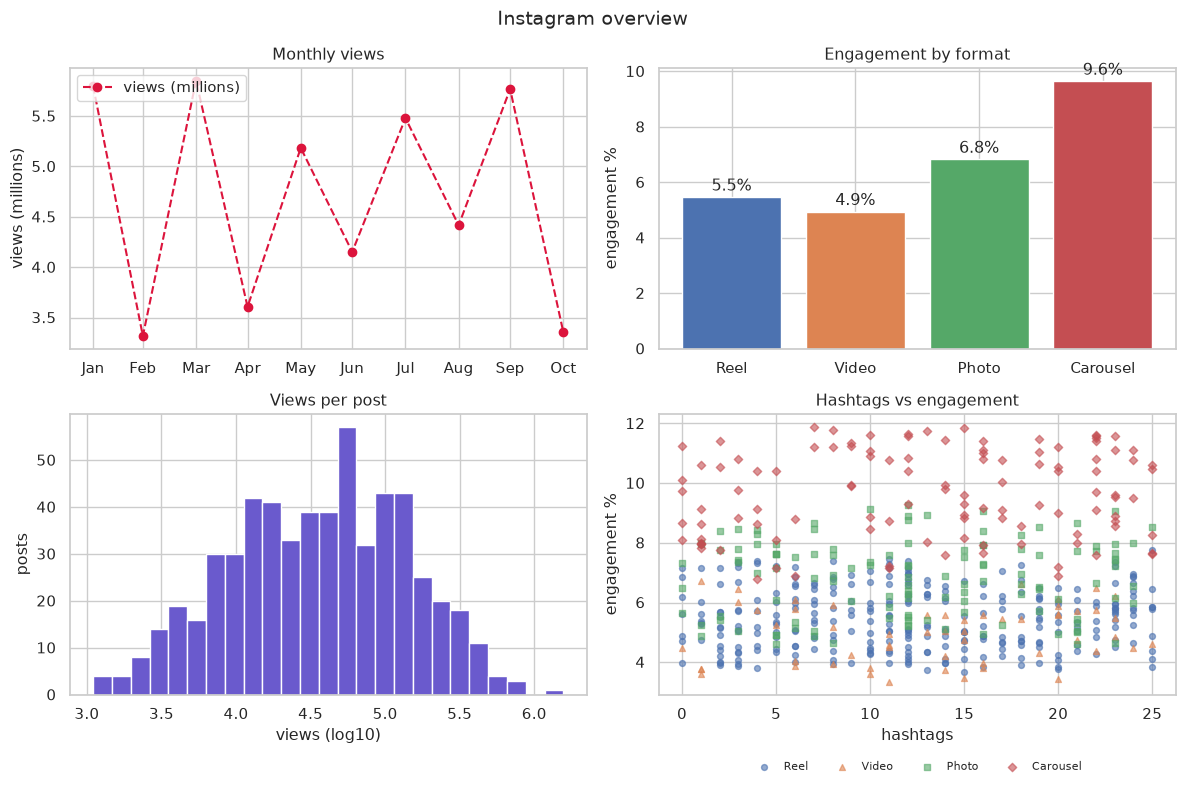

In [52]:
pal = dict(zip(order, sns.color_palette("deep", 4)))
mv = ts.views.resample("ME").sum() / 1e6
b = df.groupby("kind", observed=True).eng.mean()

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].plot(mv.index, mv.values, color="crimson", marker="o", ls="--", label="views (millions)")
ax[0, 0].set_xticks(mv.index)
ax[0, 0].set_xticklabels(mv.index.strftime("%b"))
ax[0, 0].set(title="Monthly views", ylabel="views (millions)")
ax[0, 0].legend(loc="upper left")

bars = ax[0, 1].bar(b.index, b.values, color=[pal[k] for k in b.index])
ax[0, 1].bar_label(bars, fmt="%.1f%%", padding=2)
ax[0, 1].set(title="Engagement by format", ylabel="engagement %")

ax[1, 0].hist(np.log10(df.views), bins=25, color="slateblue", edgecolor="white")
ax[1, 0].set(title="Views per post", xlabel="views (log10)", ylabel="posts")

for kd, mk in zip(order, ["o", "^", "s", "D"]):
    d = df[df.kind == kd]
    ax[1, 1].scatter(d.tags, d.eng, marker=mk, s=18, alpha=.6, color=pal[kd], label=kd)
ax[1, 1].set(title="Hashtags vs engagement", xlabel="hashtags", ylabel="engagement %")
ax[1, 1].set_xticks(range(0, 26, 5))
ax[1, 1].legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=4, fontsize=8, frameon=False)

fig.suptitle("Instagram overview", fontsize=14)
fig.tight_layout()
fig.savefig("overview.png", dpi=130, bbox_inches="tight")
plt.show()

### Line styles, ticks, labels and legends

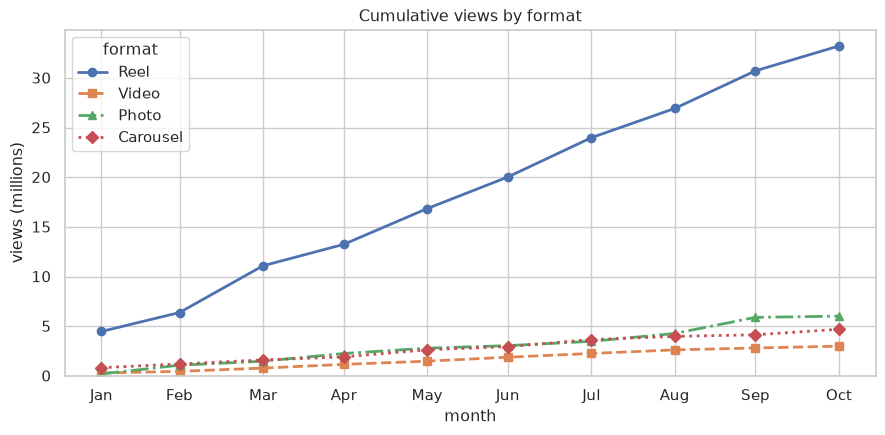

In [53]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for kd, ls, mk in zip(order, ["-", "--", "-.", ":"], ["o", "s", "^", "D"]):
    c = ts[ts.kind == kd].views.resample("ME").sum().cumsum() / 1e6
    ax.plot(c.index, c.values, ls=ls, marker=mk, lw=2, color=pal[kd], label=kd)
ax.set_xticks(c.index)
ax.set_xticklabels(c.index.strftime("%b"), rotation=0)
ax.set(title="Cumulative views by format", xlabel="month", ylabel="views (millions)", ylim=(0, None))
ax.legend(title="format", loc="upper left", frameon=True)
fig.tight_layout()
fig.savefig("cumulative_views.png", dpi=130)
plt.show()

### Seaborn: line plots

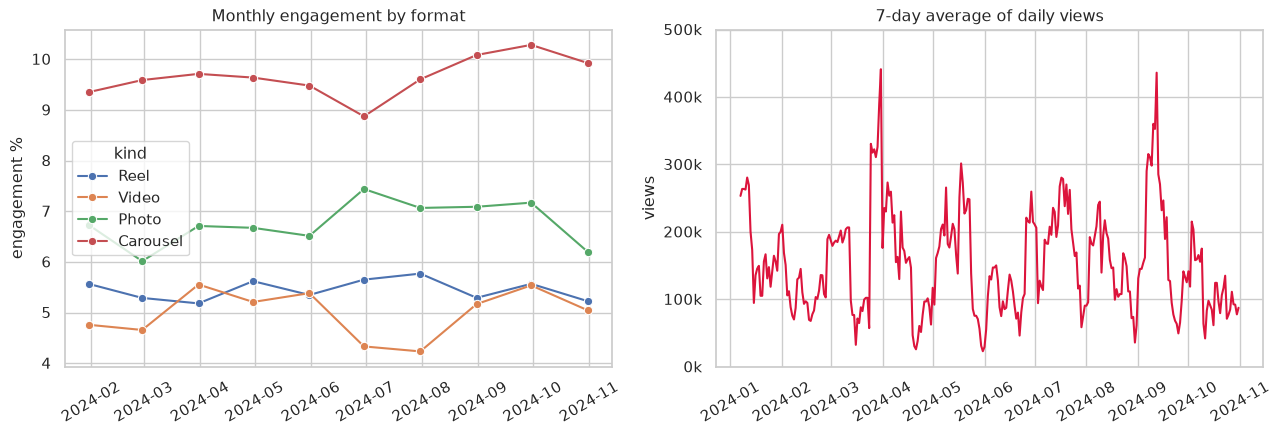

In [54]:
mm = ts.groupby("kind", observed=True).eng.resample("ME").mean().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=mm, x="date", y="eng", hue="kind", hue_order=order, palette=pal, marker="o", ax=ax[0])
ax[0].set(title="Monthly engagement by format", xlabel="", ylabel="engagement %")
sns.lineplot(x=daily.index, y=daily.rolling(7).mean(), color="crimson", ax=ax[1])
ax[1].set(title="7-day average of daily views", xlabel="", ylabel="views")
ax[1].set_yticks(ax[1].get_yticks())
ax[1].set_yticklabels([f"{t / 1000:.0f}k" for t in ax[1].get_yticks()])
for a_ in ax: a_.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

### Seaborn: bar plots

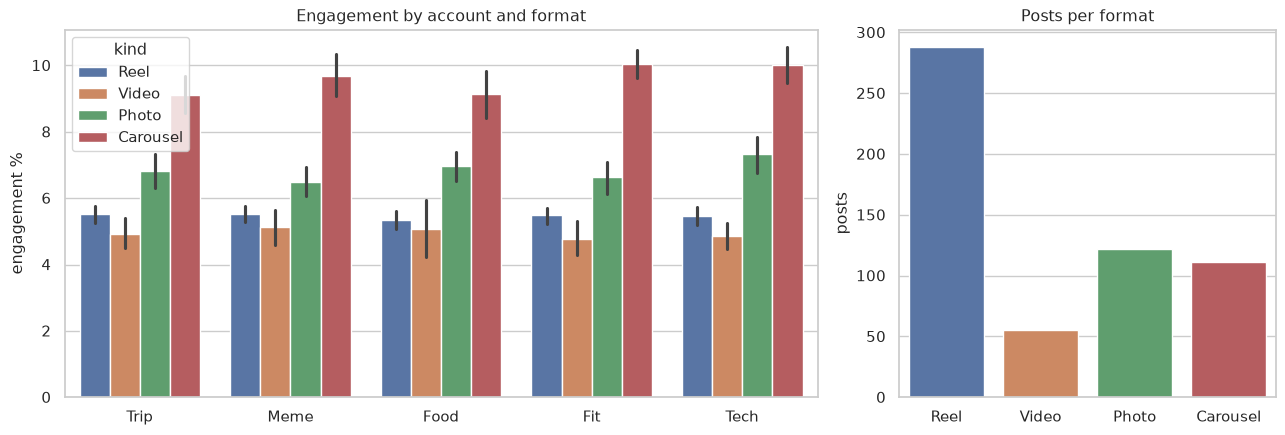

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
sns.barplot(data=df, x="user", y="eng", hue="kind", hue_order=order, palette=pal, ax=ax[0])
ax[0].set(title="Engagement by account and format", xlabel="", ylabel="engagement %")
sns.countplot(data=df, x="kind", order=order, hue="kind", palette=pal, legend=False, ax=ax[1])
ax[1].set(title="Posts per format", xlabel="", ylabel="posts")
fig.tight_layout()
plt.show()

### Seaborn: histograms and density plots

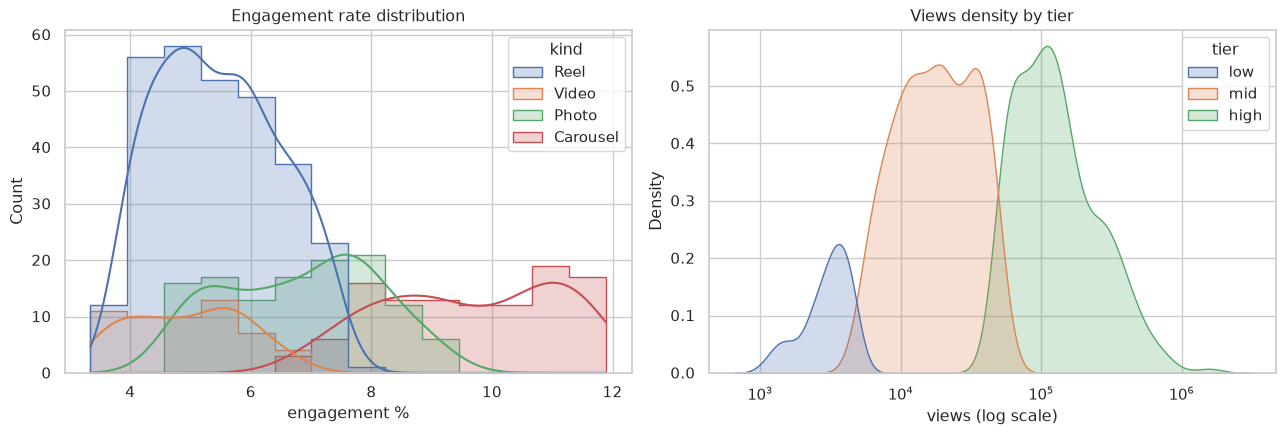

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="eng", hue="kind", hue_order=order, palette=pal, kde=True, element="step", ax=ax[0])
ax[0].set(title="Engagement rate distribution", xlabel="engagement %")
sns.kdeplot(data=df, x="views", hue="tier", hue_order=["low", "mid", "high"], log_scale=True, fill=True, ax=ax[1])
ax[1].set(title="Views density by tier", xlabel="views (log scale)")
fig.tight_layout()
plt.show()

### Seaborn: scatter and point plots

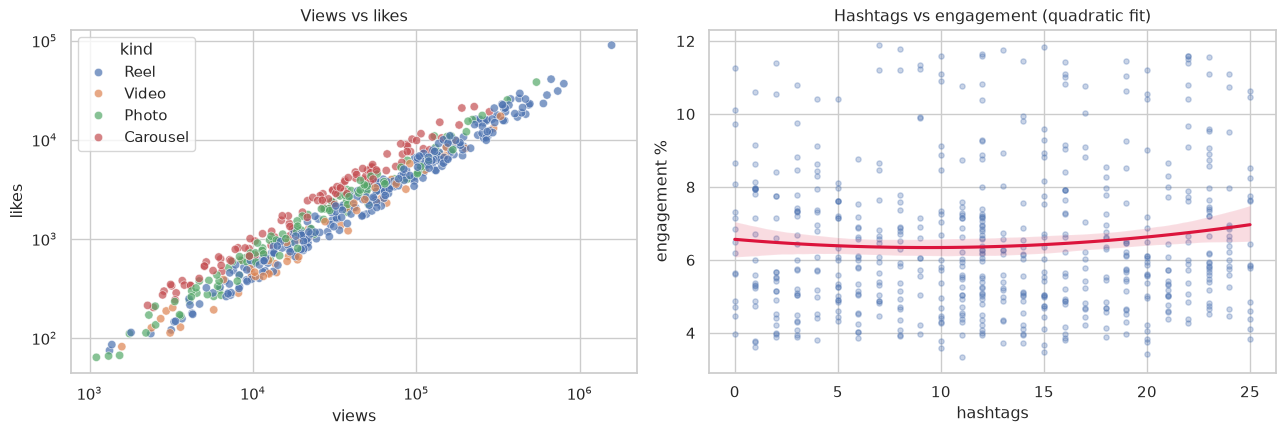

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="views", y="likes", hue="kind", hue_order=order, palette=pal, alpha=.7, ax=ax[0])
ax[0].set(xscale="log", yscale="log", title="Views vs likes")
sns.regplot(data=df, x="tags", y="eng", order=2, scatter_kws={"alpha": .3, "s": 14}, line_kws={"color": "crimson"}, ax=ax[1])
ax[1].set(title="Hashtags vs engagement (quadratic fit)", xlabel="hashtags", ylabel="engagement %")
fig.tight_layout()
plt.show()

### Seaborn: facet grids

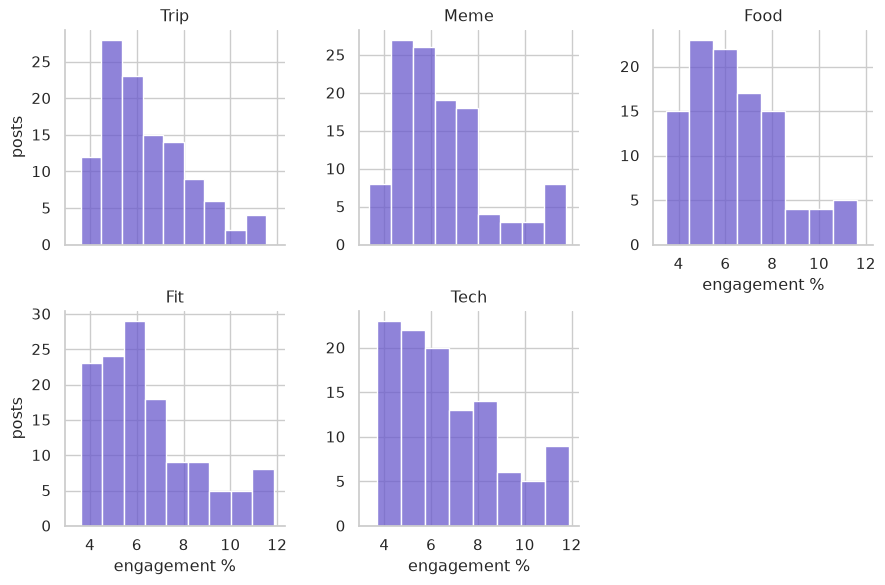

In [58]:
fg = sns.FacetGrid(df, col="user", col_wrap=3, height=3, sharey=False)
fg.map_dataframe(sns.histplot, x="eng", color="slateblue")
fg.set_titles("{col_name}")
fg.set_axis_labels("engagement %", "posts")
plt.show()

### Seaborn: categorical data

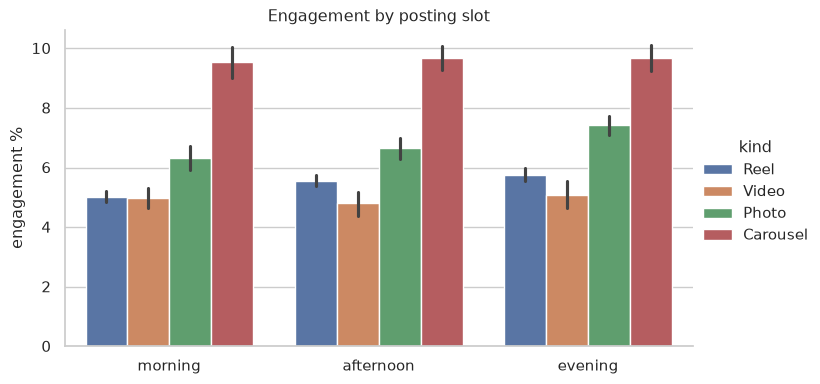

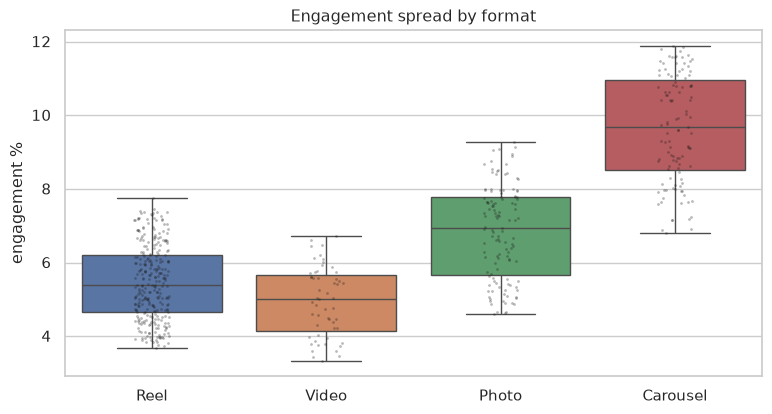

In [59]:
sns.catplot(data=df, x="slot", y="eng", hue="kind", kind="bar", order=["morning", "afternoon", "evening"],
            hue_order=order, palette=pal, height=4, aspect=1.8)
plt.title("Engagement by posting slot")
plt.ylabel("engagement %")
plt.xlabel("")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df, x="kind", y="eng", order=order, hue="kind", palette=pal, legend=False, fliersize=0, ax=ax)
sns.stripplot(data=df, x="kind", y="eng", order=order, color="k", size=2, alpha=.3, ax=ax)
ax.set(title="Engagement spread by format", xlabel="", ylabel="engagement %")
plt.show()

### Seaborn: heatmap

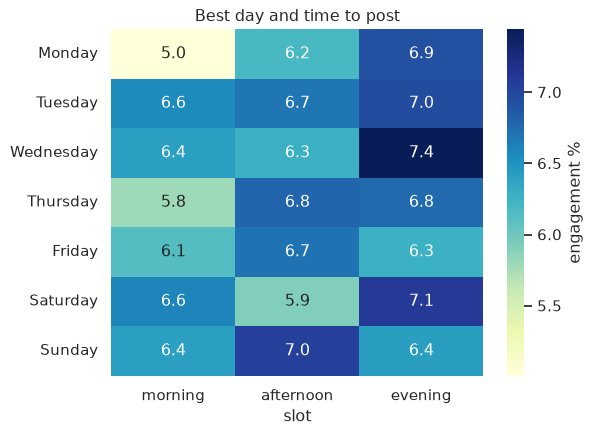

In [60]:
hm = ts.pivot_table(index=ts.index.day_name(), columns="slot", values="eng").reindex(index=days, columns=["morning", "afternoon", "evening"])
plt.figure(figsize=(6, 4.5))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "engagement %"})
plt.title("Best day and time to post")
plt.ylabel("")
plt.show()

## Putting it to use

### Helper functions

In [61]:
def top(kind=None, user=None, n=5, by="views"):
    d = df if kind is None else df[df.kind == kind]
    d = d if user is None else d[d.user == user]
    return d.nlargest(n, by)[["date", "user", "kind", "hour", "tags", "views", "eng"]]

def best_hours(kind, n=3):
    return df[df.kind == kind].groupby("hour").eng.mean().nlargest(n)

def compare(a, b):
    f = lambda k: df[df.kind == k].agg({"views": "median", "likes": "median", "comments": "median", "eng": "mean"})
    t = pd.DataFrame({a: f(a), b: f(b)})
    t["gap"] = t[a] / t[b] - 1
    return t.style.format("{:,.2f}").format("{:+.0%}", subset=["gap"])

### Top posts and format comparison

In [62]:
display(top("Reel", n=5))
compare("Reel", "Carousel")

,date,user,kind,hour,tags,views,eng
148,2024-03-25,Meme,Reel,16,6,1566306,6.11
250,2024-05-17,Meme,Reel,16,5,799170,4.84
118,2024-03-06,Meme,Reel,18,3,733539,4.50
322,2024-06-26,Meme,Reel,12,12,667809,6.69
525,2024-10-03,Meme,Reel,10,17,630122,4.69


,Reel,Carousel,gap
views,"59,256.00","29,339.00",+102%
likes,"3,218.50","2,625.00",+23%
comments,180.00,128.00,+41%
eng,5.46,9.64,-43%


### Breakout posts

In [63]:
df["lift"] = df.views / df.groupby(["user", "kind"], observed=True).views.transform("median")
bo = df[df.lift > 3]
print(f"{len(bo)} breakouts ({len(bo) / len(df):.1%} of posts): views above 3x the median of the same account and format")
display(bo.nlargest(5, "lift")[["date", "user", "kind", "hour", "views", "lift"]])
bo.kind.value_counts(normalize=True).to_frame("share of breakouts").style.format("{:.0%}")

39 breakouts (6.8% of posts): views above 3x the median of the same account and format


,date,user,kind,hour,views,lift
282,2024-06-03,Fit,Reel,17,83220,8.09
163,2024-03-31,Tech,Reel,21,440712,7.71
390,2024-07-31,Food,Reel,9,253225,7.28
181,2024-04-12,Trip,Photo,22,360417,6.97
475,2024-09-07,Fit,Photo,13,27346,6.50


,share of breakouts
kind,
Reel,56%
Photo,23%
Video,15%
Carousel,5%


### Hashtag sweet spot

,posts,med_views,eng
tag_bin,,,
0-5,126,"38,248",6.47%
6-10,99,"47,744",6.44%
11-15,138,"52,140",6.30%
16-20,107,"28,945",6.52%
21-25,106,"23,828",6.88%


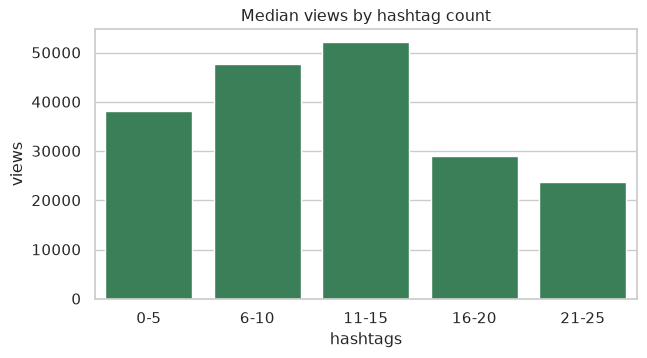

In [64]:
df["tag_bin"] = pd.cut(df.tags, [-1, 5, 10, 15, 20, 25], labels=["0-5", "6-10", "11-15", "16-20", "21-25"])
tb = df.groupby("tag_bin", observed=True).agg(posts=("eng", "size"), med_views=("views", "median"), eng=("eng", "mean"))
display(tb.style.format({"med_views": "{:,.0f}", "eng": "{:.2f}%"}).background_gradient(subset=["med_views"], cmap="Greens"))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(data=tb.reset_index(), x="tag_bin", y="med_views", color="seagreen", ax=ax)
ax.set(title="Median views by hashtag count", xlabel="hashtags", ylabel="views")
plt.show()

### Month-over-month growth

In [65]:
mo = ts.resample("ME").agg(posts=("views", "size"), views=("views", "sum"), eng=("eng", "mean"))
mo["growth"] = mo.views.pct_change()
mo.index = mo.index.strftime("%b %Y")
mo.style.format({"views": "{:,.0f}", "eng": "{:.2f}%", "growth": "{:+.1%}"}, na_rep="-").background_gradient(subset=["eng"], cmap="Blues")

,posts,views,eng,growth
date,,,,
Jan 2024,60,"5,799,024",6.32%,-
Feb 2024,51,"3,317,669",6.28%,-42.8%
Mar 2024,54,"5,851,200",6.69%,+76.4%
Apr 2024,46,"3,607,278",6.92%,-38.3%
May 2024,61,"5,184,309",6.68%,+43.7%
Jun 2024,60,"4,152,145",6.22%,-19.9%
Jul 2024,59,"5,479,896",6.61%,+32.0%
Aug 2024,59,"4,417,286",6.55%,-19.4%
Sep 2024,71,"5,767,609",6.44%,+30.6%


### Best hours per format

In [66]:
pd.DataFrame({k: best_hours(k).index.tolist() for k in order}, index=["1st", "2nd", "3rd"]).rename_axis("hour of day, best first")

,Reel,Video,Photo,Carousel
"hour of day, best first",,,,
1st,19,17,20,18
2nd,17,18,8,12
3rd,22,19,21,9


### Format scorecard

In [67]:
s = df.groupby("kind", observed=True).agg(posts=("eng", "size"), med_views=("views", "median"), med_likes=("likes", "median"), eng=("eng", "mean"))
s["best hour"] = [best_hours(k, 1).index[0] for k in s.index]
s.style.format({"med_views": "{:,.0f}", "med_likes": "{:,.0f}", "eng": "{:.2f}%"}).background_gradient(subset=["eng"], cmap="Blues").set_caption("Format scorecard")

,posts,med_views,med_likes,eng,best hour
kind,,,,,
Reel,288,"59,256","3,218",5.46%,19
Video,55,"21,968","1,078",4.94%,17
Photo,122,"22,210","1,436",6.83%,20
Carousel,111,"29,339","2,625",9.64%,18


### Findings

In [68]:
sl = df.groupby("slot").eng.mean()
print(f"Best format by engagement : {s.eng.idxmax()} ({s.eng.max():.2f}%)")
print(f"Best format by reach      : {s.med_views.idxmax()} ({s.med_views.max():,.0f} median views)")
print(f"Best slot / weekday       : {sl.idxmax()} / {wd.idxmax()}")
print(f"Hashtag sweet spot        : {tb.med_views.idxmax()} hashtags")
print(f"Breakout posts            : {len(bo)} ({bo.kind.value_counts().idxmax()} leads)")

Best format by engagement : Carousel (9.64%)
Best format by reach      : Reel (59,256 median views)
Best slot / weekday       : evening / Tuesday
Hashtag sweet spot        : 11-15 hashtags
Breakout posts            : 39 (Reel leads)
